1. Imports e sementes

In [ ]:
import sys
from pathlib import Path
import numpy as np
import torch


# Garante que a pasta raiz seja encontrada mesmo rodando de dentro de notebooks/
ROOT_DIR = Path("..").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.train import set_seed, prepare_dataset, inverse_target

RANDOM_STATE = 42
SEEDS = [42, 100, 202, 303, 404]  # 5 sementes para rodar os experimentos depois
BATCH_SIZE = 256

set_seed(RANDOM_STATE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Rodando em:", device)

Rodando em: cpu


2. Carregar e conferir o dataset de regressão

In [2]:
reg_data = prepare_dataset(
    csv_path=str(ROOT_DIR / "data" / "processed" / "dataset_regression.csv"),
    task="regression",
    target_col="TARGET",
    random_state=RANDOM_STATE,
    batch_size=BATCH_SIZE,
)

for nome in ["train", "val", "test"]:
    X_part = reg_data["scaled_splits"][f"X_{nome}"]
    y_part = reg_data["scaled_splits"][f"y_{nome}"]
    print(f"{nome:5s} -> X: {X_part.shape}, y: {y_part.shape}")

xb, yb = next(iter(reg_data["loaders"]["train"]))
print("Um batch de treino -> xb:", xb.shape, xb.dtype, "| yb:", yb.shape, yb.dtype)

train -> X: (160000, 3), y: (160000,)
val   -> X: (40000, 3), y: (40000,)
test  -> X: (50000, 3), y: (50000,)
Um batch de treino -> xb: torch.Size([256, 3]) torch.float32 | yb: torch.Size([256, 1]) torch.float32


3. Testando MLP

In [3]:
from src.models import MLP

modelo_teste = MLP(
    in_features=xb.shape[1],   # 3 na regressão
    out_features=1,
    hidden_units=(64, 32),
    activation="ReLU",
    dropout=0.0,
).to(device)

with torch.no_grad():
    saida_teste = modelo_teste(xb.to(device))

n_params = sum(p.numel() for p in modelo_teste.parameters() if p.requires_grad)
print("Saída do modelo de teste:", saida_teste.shape, saida_teste.dtype)
print("Total de parâmetros treináveis:", n_params)

Saída do modelo de teste: torch.Size([256, 1]) torch.float32
Total de parâmetros treináveis: 2369


4. Treinamento Baseline (MLP com MSELoss e Early Stopping)

In [4]:
import importlib
import src.train
importlib.reload(src.train)

from src.train import set_seed, treinar_modelo

SEMENTE_BASE = SEEDS[0]  # 42
set_seed(SEMENTE_BASE)

modelo_base = MLP(
    in_features=reg_data["n_features"],
    out_features=1,
    hidden_units=(64, 32),
    activation="ReLU",
    dropout=0.0,
).to(device)

loss_fn = torch.nn.MSELoss()
otimizador = torch.optim.Adam(modelo_base.parameters(), lr=1e-3)

resultado = treinar_modelo(
    modelo=modelo_base,
    dl_treino=reg_data["loaders"]["train"],
    dl_val=reg_data["loaders"]["val"],
    loss_fn=loss_fn,
    otimizador=otimizador,
    device=device,
    n_epocas=100,
    paciencia=15,
)

print(f"Épocas rodadas: {resultado['epocas_rodadas']} | Melhor época: {resultado['melhor_epoca']}")
print(f"Melhor perda Val (MSE padronizado): {resultado['melhor_val']:.6f}")
print(f"Tempo total: {resultado['tempo_s']:.2f}s")

Épocas rodadas: 31 | Melhor época: 16
Melhor perda Val (MSE padronizado): 0.001200
Tempo total: 47.98s


5. Curva de Perda e Análise de Generalização (Baseline)

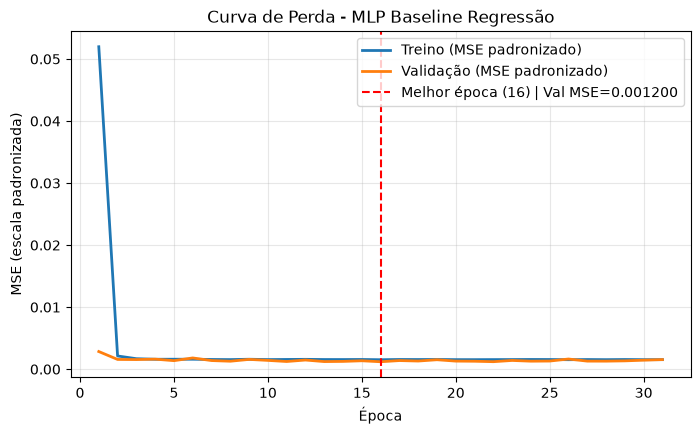

Gap (Val - Treino) na melhor época (16): -0.000325
Gap (Val - Treino) na última época (31): 0.000010


In [5]:
import matplotlib.pyplot as plt

hist_treino = resultado["historico"]["treino"]
hist_val = resultado["historico"]["val"]
epocas = range(1, len(hist_treino) + 1)
melhor_ep = resultado["melhor_epoca"]
melhor_v = resultado["melhor_val"]

# Garante que a pasta de figuras exista
fig_dir = ROOT_DIR / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 4.5))
plt.plot(epocas, hist_treino, label="Treino (MSE padronizado)", linewidth=2)
plt.plot(epocas, hist_val, label="Validação (MSE padronizado)", linewidth=2)
plt.axvline(
    melhor_ep,
    color="red",
    linestyle="--",
    label=f"Melhor época ({melhor_ep}) | Val MSE={melhor_v:.6f}",
)
plt.title("Curva de Perda - MLP Baseline Regressão")
plt.xlabel("Época")
plt.ylabel("MSE (escala padronizada)")
plt.legend()
plt.grid(True, alpha=0.3)

caminho_fig_curva = fig_dir / "mlp_reg_baseline_curva_perda.png"
plt.savefig(caminho_fig_curva, dpi=150, bbox_inches="tight")
plt.show()

gap_final_val = hist_val[-1] - hist_treino[-1]
gap_melhor_ep = hist_val[melhor_ep - 1] - hist_treino[melhor_ep - 1]
print(f"Gap (Val - Treino) na melhor época ({melhor_ep}): {gap_melhor_ep:.6f}")
print(f"Gap (Val - Treino) na última época ({len(hist_val)}): {gap_final_val:.6f}")

6. Avaliação na Escala Original (Validação)

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error

modelo_base.eval()
preds_val_scaled = []

with torch.no_grad():
    for xb, _ in reg_data["loaders"]["val"]:
        xb = xb.to(device)
        out = modelo_base(xb).cpu().numpy().ravel()
        preds_val_scaled.append(out)

y_val_pred_scaled = np.concatenate(preds_val_scaled)

# Volta para a escala original do TARGET
y_val_pred_real = inverse_target(y_val_pred_scaled, reg_data["target_scaler"])
y_val_true_real = reg_data["raw_splits"]["y_val"]

mae_real = mean_absolute_error(y_val_true_real, y_val_pred_real)
rmse_real = np.sqrt(mean_squared_error(y_val_true_real, y_val_pred_real))
medae_real = median_absolute_error(y_val_true_real, y_val_pred_real)
r2_real = r2_score(y_val_true_real, y_val_pred_real)

# MAPE com proteção caso haja valor zero em y_val_true_real
mask_nao_zero = y_val_true_real != 0
mape_real = np.mean(np.abs((y_val_true_real[mask_nao_zero] - y_val_pred_real[mask_nao_zero]) / y_val_true_real[mask_nao_zero])) * 100

print("=== Métricas na Validação (Escala Original de TARGET) ===")
print(f"MAE   : {mae_real:.4f}")
print(f"RMSE  : {rmse_real:.4f}")
print(f"MedAE : {medae_real:.4f}")
print(f"MAPE  : {mape_real:.2f}%")
print(f"R²    : {r2_real:.6f}")

=== Métricas na Validação (Escala Original de TARGET) ===
MAE   : 0.0128
RMSE  : 0.0347
MedAE : 0.0058
MAPE  : 8.39%
R²    : 0.998796


7. Gráfico de Resíduos e Real vs. Previsto (Validação)

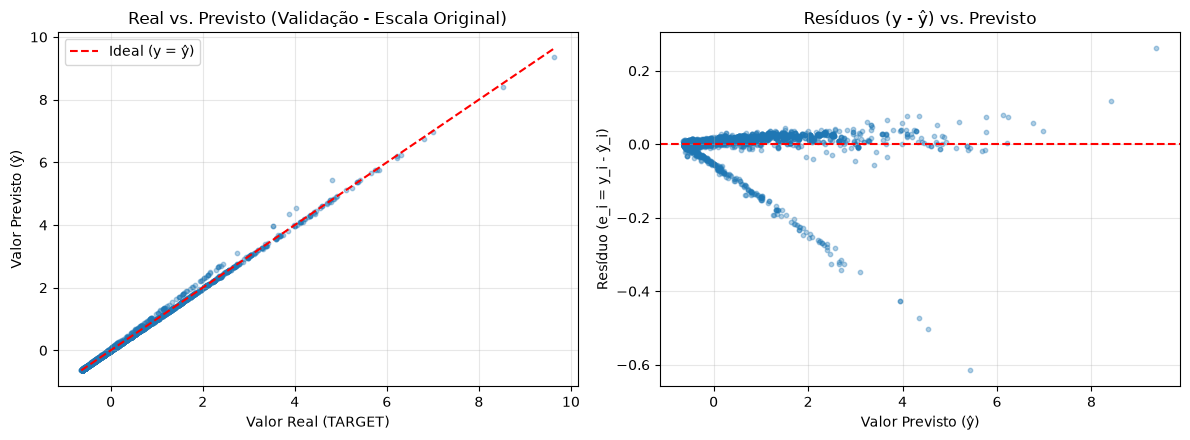

Resíduo médio: 0.001233 | Desvio padrão dos resíduos: 0.034666
Maior erro absoluto na validação: 0.7957


In [7]:
residuos_val = y_val_true_real - y_val_pred_real

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Real vs. Previsto (amostra para visualização rápida e limpa)
n_plot = min(5000, len(y_val_true_real))
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(y_val_true_real), size=n_plot, replace=False)

axes[0].scatter(y_val_true_real[idx], y_val_pred_real[idx], alpha=0.35, s=10)
min_val = min(y_val_true_real[idx].min(), y_val_pred_real[idx].min())
max_val = max(y_val_true_real[idx].max(), y_val_pred_real[idx].max())
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5, label="Ideal (y = ŷ)")
axes[0].set_title("Real vs. Previsto (Validação - Escala Original)")
axes[0].set_xlabel("Valor Real (TARGET)")
axes[0].set_ylabel("Valor Previsto (ŷ)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Resíduos vs. Previsto
axes[1].scatter(y_val_pred_real[idx], residuos_val[idx], alpha=0.35, s=10)
axes[1].axhline(0.0, color="r", linestyle="--", linewidth=1.5)
axes[1].set_title("Resíduos (y - ŷ) vs. Previsto")
axes[1].set_xlabel("Valor Previsto (ŷ)")
axes[1].set_ylabel("Resíduo (e_i = y_i - ŷ_i)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
caminho_residuos = fig_dir / "mlp_reg_baseline_residuos_val.png"
plt.savefig(caminho_residuos, dpi=150, bbox_inches="tight")
plt.show()

print(f"Resíduo médio: {residuos_val.mean():.6f} | Desvio padrão dos resíduos: {residuos_val.std():.6f}")
print(f"Maior erro absoluto na validação: {np.max(np.abs(residuos_val)):.4f}")